# Liquid crystals: Fréedericksz transition, variable retarders and twisted nematic displays

A nematic liquid crystal is a fluid of rod-like molecules that point, on
average, along a common direction, the **director** $\mathbf n$. Optically
it is a uniaxial crystal with its axis along $\mathbf n$ and a large
birefringence, $\Delta n \approx 0.2$. Mechanically it is soft: rubbed
alignment layers on the glass fix the director at the surfaces, elastic
forces carry that orientation through the cell, and a few volts across a
few micrometres turn the molecules towards the field. Liquid crystals are
the electrically tunable birefringent material of displays, spatial light
modulators, variable retarders and tunable filters.

This notebook uses the `liquid_crystals` module for the director and the
4 × 4 matrices of `crystals` (notebook 138, crystal optics) for the light:

1. the nematic E7: indices, elastic constants, the Fréedericksz threshold
   and the director profile in a field,
2. the variable retarder and the phase-only spatial light modulator:
   retardance and phase against the voltage, response times,
3. the twisted nematic (TN) cell: waveguiding, the Gooch–Tarry minima and
   the voltage–transmission curve,
4. the viewing angle of a TN display: the iso-contrast map computed with
   the 4 × 4 method, polarizers included.

The voltages are RMS values of the usual kHz square wave (the director
follows $E^2$, not the sign).

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import crystals as cr
from pyoptics import liquid_crystals as lc
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. The nematic in a field: the Fréedericksz transition

In a planar cell the director lies along the rubbing direction, tilted
by a small pretilt. A field across the cell acts on the dielectric
anisotropy $\Delta\varepsilon = \varepsilon_\parallel - \varepsilon_\perp$
(13.8 for E7) and tries to stand the molecules up, the elastic energy
(splay $K_{11}$, twist $K_{22}$, bend $K_{33}$) resists. With the tilt
$\theta(z)$ and twist $\phi(z)$ the free energy per area is

$$F = \int_0^d \tfrac12(K_{11}\cos^2\theta + K_{33}\sin^2\theta)\theta'^2
+ \tfrac12(K_{22}\cos^2\theta + K_{33}\sin^2\theta)\cos^2\theta\,\phi'^2\,dz
- \frac{\varepsilon_0V^2}{2\int_0^d dz/\varepsilon_{zz}(\theta)},$$

where the last term is the electrostatic energy at fixed voltage (the
field is not uniform, because $D_z$ is). `lc.director_profile()` minimizes
it on a grid. Without pretilt nothing happens below the **Fréedericksz
threshold** $V_\mathrm{th} = \pi\sqrt{K_{11}/\varepsilon_0\Delta\varepsilon}$,
0.95 V for E7 in any thickness; a pretilt of a few degrees rounds the
transition and decides which way the molecules turn.

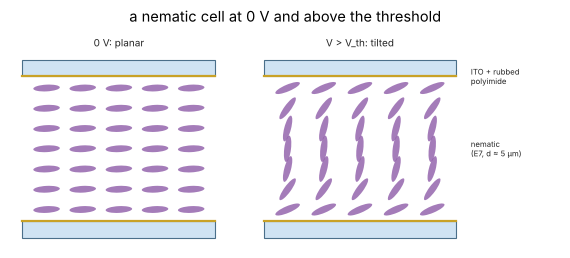

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.6))
sketch.modulator_layout(ax, "lc_cell", title="a nematic cell at 0 V and above the threshold")
plt.show()

E7: n_o = 1.5229, n_e = 1.7390 at 589 nm; V_th = 0.947 V


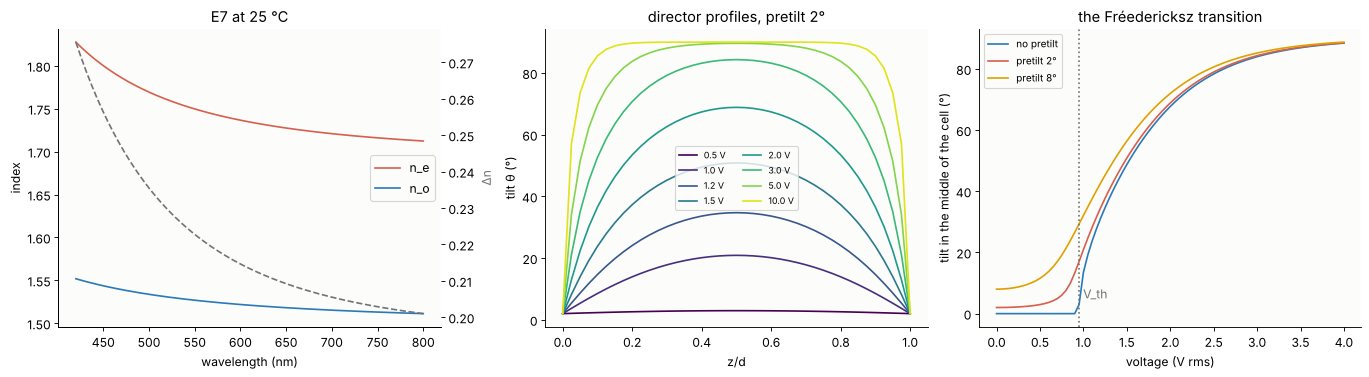

just above threshold (1.0 V): tilt profile vs sin(πz): max deviation 0.018
at 5 V the middle stands at 89.6°, the boundary layers keep the rest


In [3]:
lam_e = np.linspace(420, 800, 200)
n_o7, n_e7 = lc.e7_indices(lam_e)
V_th = lc.threshold_voltage()
print("E7: n_o = {:.4f}, n_e = {:.4f} at 589 nm; V_th = {:.3f} V".format(*lc.e7_indices(589.0), V_th))

Vs = (0.5, 1.0, 1.2, 1.5, 2.0, 3.0, 5.0, 10.0)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
ax[0].plot(lam_e, n_e7, color=RED, label="n_e"); ax[0].plot(lam_e, n_o7, color=BLUE, label="n_o")
ax0b = ax[0].twinx(); ax0b.plot(lam_e, n_e7 - n_o7, color=GREY, ls="--"); ax0b.set_ylabel("Δn", color=GREY)
ax[0].set_xlabel("wavelength (nm)"); ax[0].set_ylabel("index"); ax[0].legend(loc="center right")
ax[0].set_title("E7 at 25 °C")
cmap = plt.cm.viridis(np.linspace(0, 0.95, len(Vs)))
for V, c in zip(Vs, cmap):
    z, th, _ = lc.director_profile(V)
    ax[1].plot(z, np.degrees(th), color=c, label=f"{V} V")
ax[1].set_xlabel("z/d"); ax[1].set_ylabel("tilt θ (°)"); ax[1].legend(fontsize=8, ncol=2)
ax[1].set_title("director profiles, pretilt 2°")
Vg = np.linspace(0, 4, 81)
for pt, c, lab in ((0.0, BLUE, "no pretilt"), (np.radians(2.0), RED, "pretilt 2°"), (np.radians(8.0), ORANGE, "pretilt 8°")):
    mids = [np.degrees(lc.director_profile(v, pretilt=pt)[1].max()) for v in Vg]
    ax[2].plot(Vg, mids, color=c, label=lab)
ax[2].axvline(V_th, color=GREY, ls=":"); ax[2].text(V_th + 0.05, 5, "V_th", color=GREY)
ax[2].set_xlabel("voltage (V rms)"); ax[2].set_ylabel("tilt in the middle of the cell (°)"); ax[2].legend(fontsize=9)
ax[2].set_title("the Fréedericksz transition")
plt.show()
z, th, _ = lc.director_profile(1.0, pretilt=0.0, n_nodes=81)
print("just above threshold (1.0 V): tilt profile vs sin(πz): max deviation {:.3f}".format(
    np.abs(th/th.max() - np.sin(np.pi*z)).max()))
print("at 5 V the middle stands at {:.1f}°, the boundary layers keep the rest".format(
    np.degrees(lc.director_profile(5.0)[1].max())))

E7 has $\Delta n = 0.22$ at 589 nm, rising towards the blue. Above the
threshold the director tilts first in the middle of the cell, with the
profile $\sin(\pi z/d)$ of the lowest elastic mode; the tilt grows fast
up to 2 V and then saturates, at 5 V the middle stands upright (89.6°), but thin
boundary layers near the plates stay tilted for any voltage: the
retardance never reaches zero. With a pretilt the transition is smooth and
starts below $V_\mathrm{th}$.

## 2. Variable retarders and phase-only spatial light modulators

At normal incidence a slice with the tilt $\theta$ has the extraordinary
index $1/n_\mathrm{eff}^2 = \sin^2\theta/n_o^2 + \cos^2\theta/n_e^2$, so
the cell's retardance $2\pi/\lambda\int(n_\mathrm{eff} - n_o)\,dz$ falls
from $2\pi\Delta n\,d/\lambda$ towards zero as the voltage rises. Between
crossed polarizers at 45° to the rubbing the cell transmits
$\sin^2(\delta/2)$: a **liquid crystal variable retarder**. For light
polarized along the rubbing the same cell is a pure **phase modulator**:
this is the pixel of a phase-only LCoS spatial light modulator, whose
phase range must exceed $2\pi$ at the longest wavelength used.

half wave at 633 nm: 2.19 V; 4 x 4 at normal incidence: 0.4999 waves


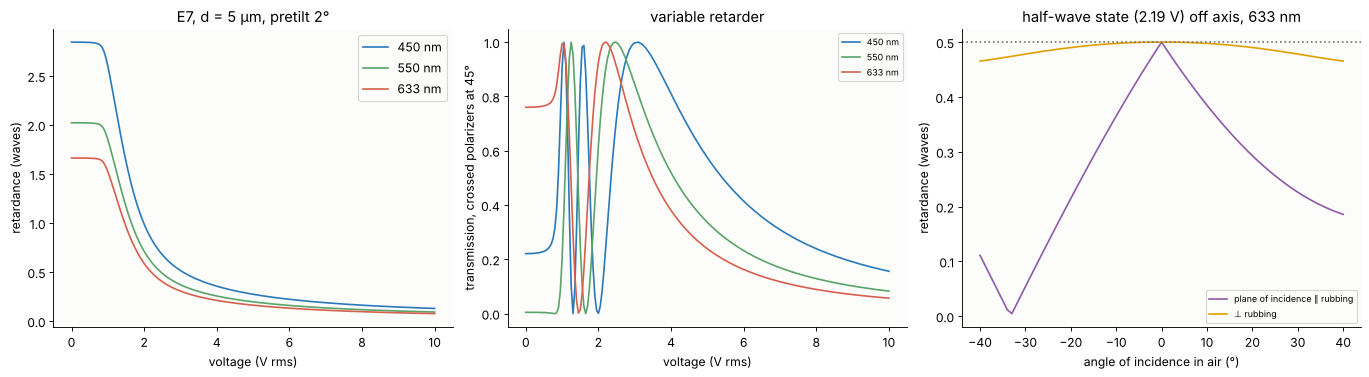

450 nm: phase range 2.85 waves at 0 V
633 nm: phase range 1.67 waves at 0 V
1064 nm: phase range 0.92 waves at 0 V
response, 5 µm: on 2.0 ms at 5 V, off 52 ms; 3 µm: on 0.7 ms, off 19 ms


In [4]:
d_cell = 5.0                                          # µm
Vg = np.concatenate([np.linspace(0, 3, 61), np.linspace(3.1, 10, 70)])
profiles = [lc.director_profile(v)[1] for v in Vg]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
for lam_, c in ((450, BLUE), (550, GREEN), (633, RED)):
    no_, ne_ = lc.e7_indices(lam_)
    dl = np.array([lc.retardance(p, d_cell, lam_*1e-3, no_, ne_) for p in profiles])
    ax[0].plot(Vg, dl/(2*np.pi), color=c, label=f"{lam_} nm")
    ax[1].plot(Vg, np.sin(dl/2)**2, color=c, label=f"{lam_} nm")
ax[0].set_xlabel("voltage (V rms)"); ax[0].set_ylabel("retardance (waves)"); ax[0].legend()
ax[0].set_title("E7, d = 5 µm, pretilt 2°")
ax[1].set_xlabel("voltage (V rms)"); ax[1].set_ylabel("transmission, crossed polarizers at 45°"); ax[1].legend(fontsize=8)
ax[1].set_title("variable retarder")
# check against the 4 x 4 method at normal incidence and see the field of view
no5, ne5 = lc.e7_indices(633.0)
V_half = lc.voltage_for_retardance(np.pi, Vg, [lc.retardance(p, d_cell, 0.633, no5, ne5) for p in profiles])
z, thh, phh = lc.director_profile(float(V_half))
ang = np.linspace(-40, 40, 81)
for az, c, lab in ((0.0, PURPLE, "plane of incidence ∥ rubbing"), (np.pi/2, ORANGE, "⊥ rubbing")):
    t, _ = cr.stack_jones(lc.cell_layers(thh, phh, d_cell, no5, ne5), 0.633, np.sin(np.radians(ang)),
                          n_in=1.0, n_out=1.0, coherent=False, azimuth=az)
    w = np.linalg.eigvals(t)
    dl = np.abs(np.angle(w[..., 0]/w[..., 1]))
    ax[2].plot(ang, dl/(2*np.pi), color=c, label=lab)
print("half wave at 633 nm: {:.2f} V; 4 x 4 at normal incidence: {:.4f} waves".format(float(V_half), dl[40]/(2*np.pi)))
ax[2].axhline(0.5, color=GREY, ls=":")
ax[2].set_xlabel("angle of incidence in air (°)"); ax[2].set_ylabel("retardance (waves)"); ax[2].legend(fontsize=8)
ax[2].set_title(f"half-wave state ({float(V_half):.2f} V) off axis, 633 nm")
plt.show()
for lam_ in (450, 633, 1064):
    no_, ne_ = lc.e7_indices(lam_)
    print("{} nm: phase range {:.2f} waves at 0 V".format(lam_, (ne_ - no_)*d_cell/(lam_*1e-3)))
on, off = lc.response_times(5e-6, 5.0)
on3, off3 = lc.response_times(3e-6, 5.0)
print("response, 5 µm: on {:.1f} ms at 5 V, off {:.0f} ms; 3 µm: on {:.1f} ms, off {:.0f} ms".format(
    on*1e3, off*1e3, on3*1e3, off3*1e3))

A 5 µm E7 cell is 1.7 waves at 633 nm and 2.85 waves at 450 nm at 0 V;
the retardance drops steeply between 1 and 2 V and creeps towards zero
above. The half wave state at 633 nm needs 2.2 V, and the 4 × 4 calculation through
40 slices agrees with the integral of $n_\mathrm{eff}$. Off the axis the
tilted director makes the retardance asymmetric in the plane of the
rubbing (the light meets the molecules more end-on on one side): a tilted
cell is a retarder for a narrow cone only, which is why LC tunable filters
are used in collimated space and LC displays need compensation films.

As a phase-only SLM the cell offers 1.7 waves at 633 nm, enough for a
$2\pi$ modulation with margin, but only 0.92 waves at 1064 nm, where
thicker cells are needed. The price of thickness is speed: the director relaxes
with $\tau_\mathrm{off} = \gamma_1d^2/(\pi^2K_{11})$, 52 ms for 5 µm and 19 ms
for 3 µm, while switching on is driven by the field and much faster
(2 ms and 0.7 ms at 5 V).
LCoS devices use thin cells of fast mixtures for frame rates of 60 to
several hundred Hz; notebook 73 (wavefront shaping) uses such an SLM.

## 3. The twisted nematic cell

When the rubbing directions of the two plates are crossed, the director
twists by 90° through the cell. If the twist is slow compared to the
birefringent phase, light polarized along the director at the entrance
follows it and leaves rotated by 90° (Mauguin's waveguiding). The exact
transmission between parallel polarizers is the Gooch–Tarry formula

$$T_\parallel = \frac{\sin^2\left(\frac{\pi}{2}\sqrt{1 + u^2}\right)}{1 + u^2},\qquad u = \frac{2d\,\Delta n}{\lambda},$$

which vanishes at $u = \sqrt3, \sqrt{15}, \dots$: the first and second
minima, used to design the cell gap. Between crossed polarizers the cell
is bright at 0 V (normally white); a voltage stands the molecules up, the
guiding stops and the display turns black.

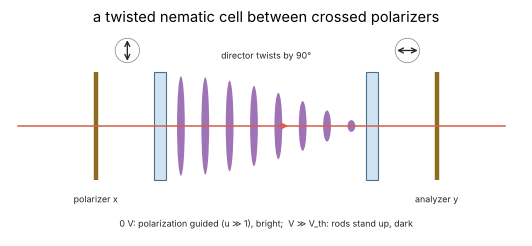

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.4))
sketch.modulator_layout(ax, "tn_cell", title="a twisted nematic cell between crossed polarizers")
plt.show()

first minimum d = 2.14 µm, second minimum d = 4.78 µm (E7, 550 nm)


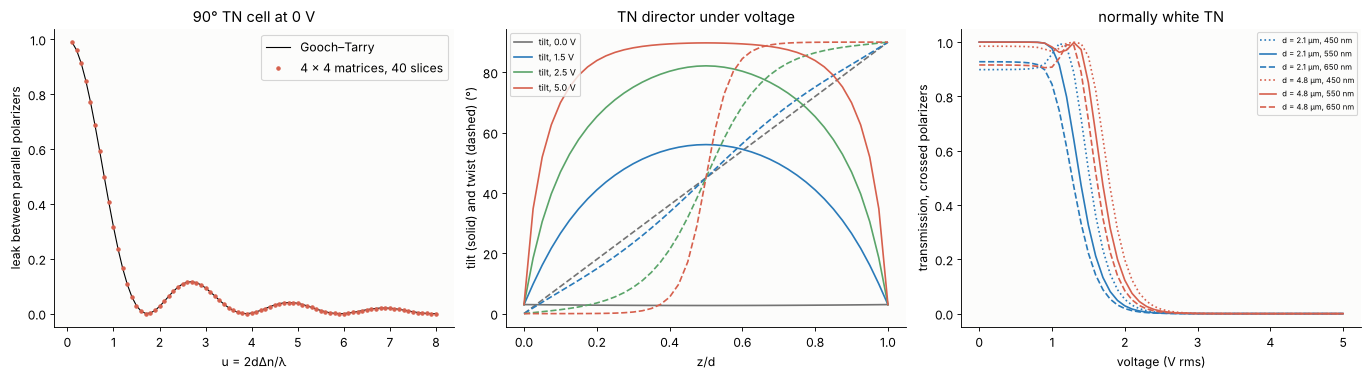

In [6]:
lam_t = 0.55
no_t, ne_t = lc.e7_indices(550.0)
dn_t = ne_t - no_t
d1 = np.sqrt(3)*lam_t/(2*dn_t)
d2 = np.sqrt(15)*lam_t/(2*dn_t)
print("first minimum d = {:.2f} µm, second minimum d = {:.2f} µm (E7, 550 nm)".format(d1, d2))
z, th0, ph0 = lc.director_profile(0.0, pretilt=0.0, twist=np.pi/2)
u = np.linspace(0.1, 8, 80)
T4 = []
for uu in u:
    d = uu*lam_t/(2*dn_t)
    t, _ = cr.stack_jones(lc.cell_layers(th0, ph0, d, no_t, ne_t), lam_t, n_in=1.5, n_out=1.5, coherent=False)
    E = t @ np.array([1.0, 0.0])
    T4.append(abs(E[0])**2/np.sum(np.abs(E)**2))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
ax[0].plot(u, lc.gooch_tarry(u), color="k", lw=1, label="Gooch–Tarry")
ax[0].plot(u, T4, "o", ms=3, color=RED, label="4 × 4 matrices, 40 slices")
ax[0].set_xlabel("u = 2dΔn/λ"); ax[0].set_ylabel("leak between parallel polarizers"); ax[0].legend()
ax[0].set_title("90° TN cell at 0 V")
# director of the TN cell under voltage (second minimum cell)
for V, c in ((0.0, GREY), (1.5, BLUE), (2.5, GREEN), (5.0, RED)):
    z, th, ph = lc.director_profile(V, pretilt=np.radians(3.0), twist=np.pi/2)
    ax[1].plot(z, np.degrees(th), color=c, label=f"tilt, {V} V")
    ax[1].plot(z, np.degrees(ph), color=c, ls="--")
ax[1].set_xlabel("z/d"); ax[1].set_ylabel("tilt (solid) and twist (dashed) (°)"); ax[1].legend(fontsize=8)
ax[1].set_title("TN director under voltage")
# voltage - transmission curves between crossed polarizers (normally white)
VT = np.linspace(0, 5, 51)
tn_prof = {}
for d, c in ((d1, BLUE), (d2, RED)):
    for lam_, ls in ((0.45, ":"), (0.55, "-"), (0.65, "--")):
        no_, ne_ = lc.e7_indices(lam_*1e3)
        Tv = []
        for V in VT:
            if V not in tn_prof:
                tn_prof[V] = lc.director_profile(V, pretilt=np.radians(3.0), twist=np.pi/2)
            _, th, ph = tn_prof[V]
            t, _ = cr.stack_jones(lc.cell_layers(th, ph, d, no_, ne_), lam_, n_in=1.5, n_out=1.5, coherent=False)
            E = t @ np.array([1.0, 0.0])
            Tv.append(abs(E[1])**2/np.sum(np.abs(E)**2))
        ax[2].plot(VT, Tv, color=c, ls=ls, label=f"d = {d:.1f} µm, {lam_*1e3:.0f} nm")
ax[2].set_xlabel("voltage (V rms)"); ax[2].set_ylabel("transmission, crossed polarizers"); ax[2].legend(fontsize=7)
ax[2].set_title("normally white TN")
plt.show()

The 4 × 4 calculation through the twisted director reproduces the
Gooch–Tarry formula. A first minimum cell (2.1 µm of E7) guides
perfectly only near 550 nm and transmits about 90 % of the blue and red
light at 0 V; the second minimum cell (4.8 µm) transmits 98 % or more over
the whole spectrum but is slower. Under voltage the
tilt in the middle rises and the twist concentrates in the middle of the
cell, where the molecules stand up; the guiding breaks and the
transmission between crossed polarizers drops from 1 to a few percent
between about 1.2 and 2.2 V. The steepness of this curve once limited passive
matrix displays to a few hundred lines (Alt–Pleshko); active matrix
TFT displays switch every pixel through its own transistor.

## 4. The viewing angle of a TN display

Off the axis the light meets the standing molecules of the dark state
obliquely, and the residual birefringence lets light through: the
contrast of TN displays falls off with the viewing angle, and at some
angles the grey levels invert. The polarizers themselves are not ideal
off the axis either. All of this is in the 4 × 4 method: the polarizers
are absorbing uniaxial layers (a dichroic "O-type" polarizer, 20 µm with
$\kappa_e = 0.02$ along its absorption axis, an extinction of $10^{-4}$), and each direction of view
is a plane wave through polarizer, 40 slices of the director profile and
analyzer.

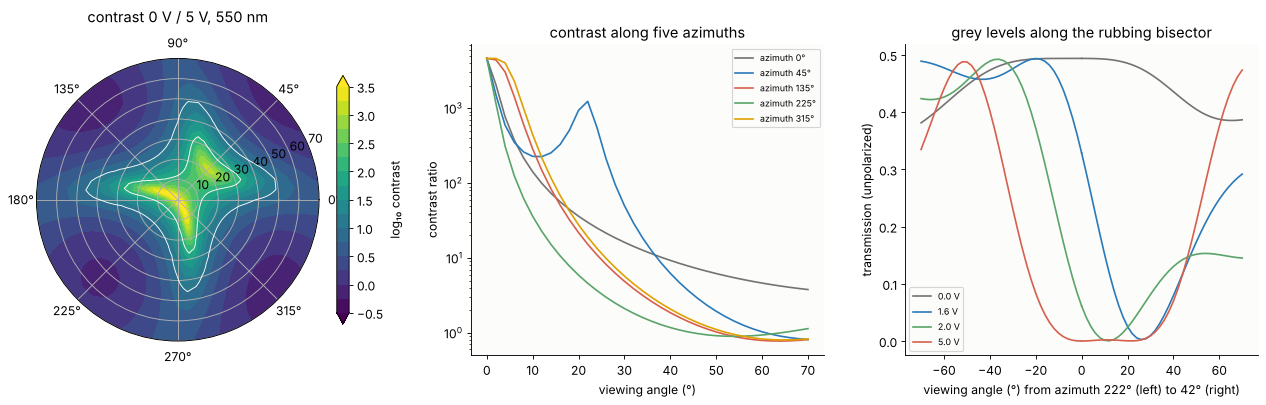

on-axis: white 0.494, black 1.07e-04, contrast 4627
contrast ≥ 100: up to 6° in the worst azimuth, 32° in the best
contrast ≥ 10: up to 16° in the worst azimuth, 48° in the best


In [7]:
d_tn = d2                                              # the second minimum cell
no_v, ne_v = lc.e7_indices(550.0)
pol_x = cr.uniaxial_eps(1.5, 1.5 + 0.02j, (0.0, 1.0, 0.0))   # transmits x, absorbs y
pol_y = cr.uniaxial_eps(1.5, 1.5 + 0.02j, (1.0, 0.0, 0.0))   # transmits y
theta_v = np.linspace(0, 70, 36)
phi_v = np.radians(np.arange(0, 361, 6))
TH, PH = np.meshgrid(np.radians(theta_v), phi_v)
xi = np.sin(TH)
states = {}
for V in (0.0, 1.6, 2.0, 5.0):
    _, th, ph = lc.director_profile(V, pretilt=np.radians(3.0), twist=np.pi/2)
    layers = [(pol_x, 20.0)] + lc.cell_layers(th, ph, d_tn, no_v, ne_v) + [(pol_y, 20.0)]
    t, _ = cr.stack_jones(layers, 0.55, xi, n_in=1.5, n_out=1.5, coherent=False, azimuth=PH)
    # unpolarized light: half the sum of the squared matrix elements
    states[V] = 0.5*np.sum(np.abs(t)**2, axis=(-2, -1))
CR = states[0.0]/states[5.0]
fig = plt.figure(figsize=(16, 5))
axp = fig.add_subplot(1, 3, 1, projection="polar")
cs = axp.contourf(PH, TH*180/np.pi, np.log10(CR), levels=np.linspace(-0.5, 3.5, 17), cmap="viridis", extend="both")
axp.contour(PH, TH*180/np.pi, CR, levels=[10, 100], colors="w", linewidths=0.8)
fig.colorbar(cs, ax=axp, label="log₁₀ contrast", shrink=0.8)
axp.set_title("contrast 0 V / 5 V, 550 nm", pad=12)
ax2 = fig.add_subplot(1, 3, 2)
for phd, c in ((0, GREY), (45, BLUE), (135, RED), (225, GREEN), (315, ORANGE)):
    i = int(phd/6)
    ax2.semilogy(theta_v, CR[i], color=c, label=f"azimuth {phd}°")
ax2.set_xlabel("viewing angle (°)"); ax2.set_ylabel("contrast ratio"); ax2.legend(fontsize=8)
ax2.set_title("contrast along five azimuths")
ax3 = fig.add_subplot(1, 3, 3)
for V, c in ((0.0, GREY), (1.6, BLUE), (2.0, GREEN), (5.0, RED)):
    i_up, i_dn = int(42/6), int(222/6)
    ax3.plot(theta_v, states[V][i_up], color=c, label=f"{V} V")
    ax3.plot(-theta_v, states[V][i_dn], color=c)
ax3.set_xlabel("viewing angle (°) from azimuth 222° (left) to 42° (right)"); ax3.set_ylabel("transmission (unpolarized)")
ax3.legend(fontsize=8); ax3.set_title("grey levels along the rubbing bisector")
plt.tight_layout()
plt.show()
print("on-axis: white {:.3f}, black {:.2e}, contrast {:.0f}".format(states[0.0][0, 0], states[5.0][0, 0], CR[0, 0]))
for lim in (100, 10):
    ok = CR >= lim
    print("contrast ≥ {}: up to {:.0f}° in the worst azimuth, {:.0f}° in the best".format(
        lim, min(theta_v[ok[i]].max() for i in range(len(phi_v))), max(theta_v[ok[i]].max() for i in range(len(phi_v)))))

On the axis the display reaches a contrast of 4600:1, limited by the
extinction of the polarizers. Off the axis it falls quickly and
unevenly: a contrast of 100 holds only within 6° in the worst azimuth
and 32° in the best one, along the bisector of the rubbing directions
(42°), and a contrast of 10 within 16° to 48°; at large angles in the
diagonal directions the contrast drops below 1 (the white holes in the
map, where black is brighter than white). The grey levels along the
rubbing bisector show the inversion: at 1.6 and 2 V the curves cross the
white and black states, so from one side a mid grey looks brighter than
white or darker than black. This is why TN
panels survive only in cheap monitors and why IPS (in-plane switching)
and VA (vertically aligned) cells with compensation films took over;
all of them are computed the same way, with other director profiles and
more layers in the stack.

## Summary

- **Nematic:** a uniaxial crystal with $\Delta n \approx 0.2$ and its axis
  along the director; E7: $\Delta n = 0.22$, $\Delta\varepsilon = 13.8$,
  Fréedericksz threshold 0.95 V independent of the thickness.
- **Director in a field:** minimizing the Frank energy at fixed voltage
  gives $\sin(\pi z/d)$ just above the threshold and thin tilted boundary
  layers at high voltage.
- **Variable retarder and SLM:** a 5 µm cell runs from 1.7 waves to near
  zero at 633 nm between 1 and 10 V; the half wave state is at 2.2 V. As a
  phase modulator it needs $\Delta n\,d > \lambda$; it relaxes in tens of
  milliseconds ($\propto d^2$).
- **TN cell:** Gooch–Tarry minima at $u = \sqrt3, \sqrt{15}$, reproduced by
  the 4 × 4 method through the twisted director; normally white,
  switched between 1.5 and 3 V.
- **Viewing angle:** the 4 × 4 method with absorbing polarizers gives the
  iso-contrast map and the grey level inversion of a TN display: 4600:1
  on the axis, 10:1 within only 16° to 48°.

In [8]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 15 s


## References

- P. Yeh and C. Gu, *Optics of Liquid Crystal Displays*, 2nd ed., Wiley
  (2010).
- D.-K. Yang and S.-T. Wu, *Fundamentals of Liquid Crystal Devices*, 2nd
  ed., Wiley (2015).
- P. G. de Gennes and J. Prost, *The Physics of Liquid Crystals*, 2nd ed.,
  Oxford University Press (1993).
- C. H. Gooch and H. A. Tarry, "The optical properties of twisted nematic
  liquid crystal structures with twist angles ≤ 90 degrees", J. Phys. D 8,
  1575–1584 (1975).
- A. Lien, "Extended Jones matrix representation for the twisted nematic
  liquid-crystal display at oblique incidence", Appl. Phys. Lett. 57,
  2767–2769 (1990).
- J. Li and S.-T. Wu, "Extended Cauchy equations for the refractive
  indices of liquid crystals", J. Appl. Phys. 95, 896–901 (2004).
- G. Lazarev, A. Hermerschmidt, S. Krüger and S. Osten, "LCOS spatial
  light modulators: trends and applications", in *Optical Imaging and
  Metrology*, Wiley-VCH (2012).